# Spam Classifier: NLP Text Preprocessing → TF-IDF → Naive Bayes

**Pipeline**
1. Load data
2. Text preprocessing: lowercasing, HTML removal, URL removal, chat-word treatment, emoji handling, punctuation removal, spelling correction, stop-word removal
3. Tokenization → Stemming vs Lemmatization (we use **lemmatization**)
4. Text → Vector: One-Hot, Multi-Hot, Bag of Words, **TF-IDF** (we use this)
5. Multinomial Naive Bayes
6. Save the model for the Streamlit app

## 0. Setup

In [10]:
pip install nltk emoji pyspellchecker scikit-learn pandas matplotlib seaborn joblib

  Using cached pyspellchecker-0.9.1-py3-none-any.whl.metadata (9.3 kB)
Using cached pyspellchecker-0.9.1-py3-none-any.whl (7.2 MB)

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [11]:
# !pip install nltk emoji pyspellchecker scikit-learn pandas matplotlib seaborn joblib
import re, string, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import emoji
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer, WordNetLemmatizer
from spellchecker import SpellChecker

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(pkg, quiet=True)

pd.set_option("display.max_colwidth", 120)

## 1. Load the dataset

In [13]:
df = pd.read_csv("/Users/pradipwasre/Desktop/Data-Science-/8_NLP/spam-nlp-aws/data/spam_dataset.csv")
df.head(10)

,text,label
0,Great job on the presentation today!! The client loved it 🍕,ham
1,<b>SALE!!!</b> Designer watches at 30% discount. Buy now www.cheap-meds-online.ru,spam
2,Double ur money in 24 hrs guaranteed!!! 100% risk free. Join now http://bit.ly/fr33-pr1ze 🎁,spam
3,The flgiht lands at 3 pm. Can you pick me up from the airport?,ham
4,Good morning! Hope you slept well. Coffee later at 7 pm? 🍕,ham
5,FREE entry in our weekly draw to win cruise trip. Txt WIN to 80086 now!!! 🎉,spam
6,Earn easy money fast!!! Invest $500 and get 10x returns in 7 days. Visit http://click4cash.info,spam
7,"Hey, are we still meeting for lunch tomorrow at 8 pm? 😊",ham
8,Happy birthday!!! Hope u have an amazing day 😊,ham
9,"plz send me the notes from yesterday's lecture, i was sick",ham


In [3]:
df.shape, df["label"].value_counts()

((300, 2),
 label
 ham     150
 spam    150
 Name: count, dtype: int64)

In [14]:
df["label_num"] = df["label"].map({"ham": 0, "spam": 1})
df.isna().sum()

text         0
label        0
label_num    0
dtype: int64

## 2. Text preprocessing (step by step)

### 2.1 Lowercasing

In [15]:
def to_lower(text):
    return text.lower()

sample = df["text"].iloc[0]
sample, to_lower(sample)

('Great job on the presentation today!! The client loved it 🍕',
 'great job on the presentation today!! the client loved it 🍕')

### 2.2 Remove HTML tags

In [17]:
def remove_html(text):
    return re.sub(r"<.*?>", " ", text)

html_example = "<p>Dear customer, your account is <b>suspended</b>. Verify now.</p>"
remove_html(html_example)

' Dear customer, your account is  suspended . Verify now. '

### 2.3 Remove URLs

In [18]:
def remove_urls(text):
    return re.sub(r"(https?://\S+|www\.\S+|\b\S+\.(com|biz|ru|xyz|top|info|io|co)\S*)", " ", text)

remove_urls("Click http://bit.ly/fr33-pr1ze or visit www.cheap-meds-online.ru now")

'Click   or visit   now'

### 2.4 Chat word treatment (slang → full form)

In [19]:
chat_words = {
    "u": "you", "ur": "your", "r": "are", "plz": "please", "pls": "please", "thx": "thanks",
    "asap": "as soon as possible", "b4": "before", "2": "to", "4": "for", "tonite": "tonight",
    "lol": "laughing out loud", "lmao": "laughing", "omg": "oh my god", "brb": "be right back",
    "gtg": "got to go", "ttyl": "talk to you later", "idk": "i do not know", "btw": "by the way",
    "af": "very", "gonna": "going to", "wanna": "want to", "txt": "text", "msg": "message",
    "yr": "your", "bro": "brother", "tmrw": "tomorrow", "fr33": "free", "acount": "account",
}

def chat_conversion(text):
    return " ".join(chat_words.get(w, w) for w in text.split())

chat_conversion("u r the winner plz claim ur prize asap")

'you are the winner please claim your prize as soon as possible'

### 2.5 Handling emojis
Two options: **remove** them, or **convert them to text** (`😊` → `smiling face`). Converting keeps the signal (e.g. 🤑💰 are common in spam), so we convert.

In [21]:
def handle_emoji(text, mode="convert"):
    if mode == "remove":
        return emoji.replace_emoji(text, replace="")
    text = emoji.demojize(text, delimiters=(" ", " "))   # 🤑 -> " money-mouth_face "
    return text.replace("_", " ")

handle_emoji("You won 💰🎉 call me 😊"), handle_emoji("You won 💰🎉 call me 😊", mode="remove")

('You won  money bag  party popper  call me  smiling face with smiling eyes ',
 'You won  call me ')

### 2.6 Remove punctuation

In [27]:
def remove_punct(text):
    return text.translate(str.maketrans("", "", string.punctuation))

remove_punct("Win!!! $1000 now, click-here.")

'Win 1000 now clickhere'

### 2.7 Spelling correction

In [28]:
spell = SpellChecker()
_spell_cache = {}

def correct_spelling(text):
    out = []
    for w in text.split():
        if w not in _spell_cache:
            if w.isalpha() and w in spell.unknown([w]):
                _spell_cache[w] = spell.correction(w) or w
            else:
                _spell_cache[w] = w
        out.append(_spell_cache[w])
    return " ".join(out)

correct_spelling("your appointment is confrimed and your acount is limitted")

'your appointment is confirmed and your count is limited'

### 2.8 Removing stop words

In [29]:
stop_words = set(stopwords.words("english"))

def remove_stopwords(text):
    return " ".join(w for w in text.split() if w not in stop_words)

remove_stopwords("this is a very important message for you and me")

'important message'

## 3. Tokenization

In [30]:
def tokenize(text):
    return word_tokenize(text)

tokenize("claim your free prize now")

['claim', 'your', 'free', 'prize', 'now']

## 4. Stemming vs Lemmatization
- **Stemming** chops suffixes by rules → fast, but may produce non-words (`"winning"→"win"`, `"prize"→"prize"`, `"happily"→"happili"`).
- **Lemmatization** uses a dictionary → always a real word (`"better"→"good"`, `"running"→"run"`).

**We are going to use lemmatization.**

In [34]:
stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

def stem_tokens(tokens):
    return [stemmer.stem(t) for t in tokens]

def lemmatize_tokens(tokens):
    # try as verb first (running -> run), then as noun (prizes -> prize)
    return [lemmatizer.lemmatize(lemmatizer.lemmatize(t, pos="v"), pos="n") for t in tokens]

words = ["winning", "claimed", "prizes", "happily", "studies", "meetings", "better", "running"]
pd.DataFrame({"word": words, "stem": stem_tokens(words), "lemma": lemmatize_tokens(words)})

,word,stem,lemma
0,winning,win,win
1,claimed,claim,claim
2,prizes,prize,prize
3,happily,happili,happily
4,studies,studi,study
5,meetings,meet,meeting
6,better,better,better
7,running,run,run


## 5. Full preprocessing pipeline

In [35]:
def preprocess(text, return_tokens=False):
    text = to_lower(text)
    text = remove_html(text)
    text = remove_urls(text)
    text = chat_conversion(text)
    text = handle_emoji(text, mode="convert")
    text = remove_punct(text)
    text = re.sub(r"\d+", " ", text)          # drop standalone numbers
    text = re.sub(r"\s+", " ", text).strip()
    text = correct_spelling(text)
    text = remove_stopwords(text)
    tokens = tokenize(text)
    tokens = lemmatize_tokens(tokens)
    return tokens if return_tokens else " ".join(tokens)

preprocess("<p>CONGRATULATIONS!!! U have WON a $1000 gift card. Click http://bit.ly/fr33-pr1ze to claim now 🎉</p>")

'congratulation gift card click claim party popper'

In [36]:
df["clean_text"] = df["text"].apply(preprocess)
df[["text", "clean_text", "label"]].head(10)

,text,clean_text,label
0,Great job on the presentation today!! The client loved it 🍕,great job presentation today client love pizza,ham
1,<b>SALE!!!</b> Designer watches at 30% discount. Buy now www.cheap-meds-online.ru,sale designer watch discount buy,spam
2,Double ur money in 24 hrs guaranteed!!! 100% risk free. Join now http://bit.ly/fr33-pr1ze 🎁,double money guarantee risk free join wrap gift,spam
3,The flgiht lands at 3 pm. Can you pick me up from the airport?,flight land pm pick airport,ham
4,Good morning! Hope you slept well. Coffee later at 7 pm? 🍕,good morning hope sleep well coffee later pm pizza,ham
5,FREE entry in our weekly draw to win cruise trip. Txt WIN to 80086 now!!! 🎉,free entry weekly draw win cruise trip text win party popper,spam
6,Earn easy money fast!!! Invest $500 and get 10x returns in 7 days. Visit http://click4cash.info,earn easy money fast invest get x return day visit,spam
7,"Hey, are we still meeting for lunch tomorrow at 8 pm? 😊",hey still meet lunch tomorrow pm smile face smile eye,ham
8,Happy birthday!!! Hope u have an amazing day 😊,happy birthday hope amaze day smile face smile eye,ham
9,"plz send me the notes from yesterday's lecture, i was sick",please send note yesterday lecture sick,ham


### Quick look at the cleaned data

In [37]:
df["n_tokens"] = df["clean_text"].str.split().str.len()
df.groupby("label")["n_tokens"].describe()

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
ham,150.0,7.293333,1.985000,4.0,5.25,8.0,9.0,12.0
spam,150.0,8.386667,2.107152,5.0,6.00,8.0,10.0,14.0


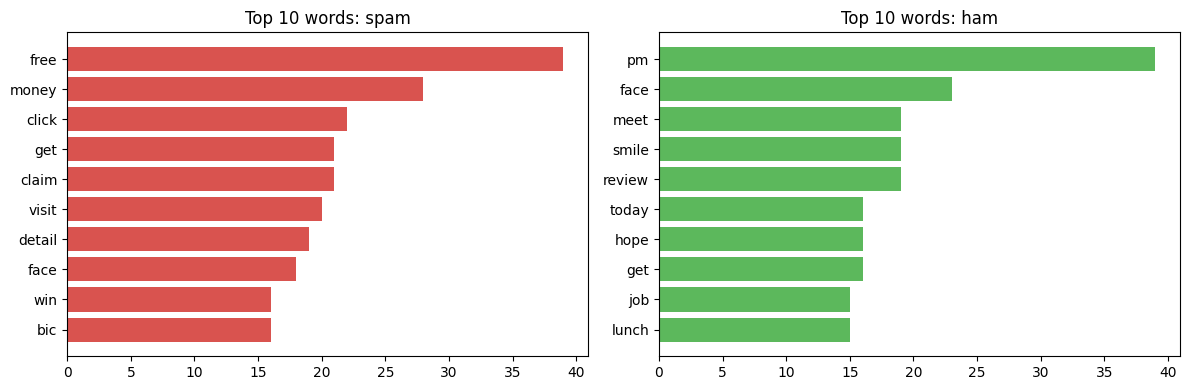

In [18]:
from collections import Counter
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, lab, color in zip(axes, ["spam", "ham"], ["#d9534f", "#5cb85c"]):
    top = Counter(" ".join(df.loc[df.label == lab, "clean_text"]).split()).most_common(10)
    ax.barh([w for w, _ in top][::-1], [c for _, c in top][::-1], color=color)
    ax.set_title(f"Top 10 words: {lab}")
plt.tight_layout()
plt.show()

## 6. Text → Vector
Demonstrated on 3 tiny documents first so the output is readable. Then we apply TF-IDF on the real data.

In [38]:
docs = ["win free prize now", "free lunch tomorrow", "meeting tomorrow now"]

### 6.1 One-Hot Encoding
Each **word** becomes a vector with a single `1` at its vocabulary index. A document becomes a matrix (`n_words × vocab_size`).

In [39]:
vocab = sorted({w for d in docs for w in d.split()})
word2idx = {w: i for i, w in enumerate(vocab)}

def one_hot(doc):
    mat = np.zeros((len(doc.split()), len(vocab)), dtype=int)
    for row, w in enumerate(doc.split()):
        mat[row, word2idx[w]] = 1
    return pd.DataFrame(mat, index=doc.split(), columns=vocab)

one_hot(docs[0])

,free,lunch,meeting,now,prize,tomorrow,win
win,0,0,0,0,0,0,1
free,1,0,0,0,0,0,0
prize,0,0,0,0,1,0,0
now,0,0,0,1,0,0,0


### 6.2 Multi-Hot Encoding
One vector per **document**: `1` if the word is present, else `0` (no counts).

In [40]:
multi_hot = CountVectorizer(binary=True)
pd.DataFrame(multi_hot.fit_transform(docs).toarray(), columns=multi_hot.get_feature_names_out(), index=docs)

,free,lunch,meeting,now,prize,tomorrow,win
win free prize now,1,0,0,1,1,0,1
free lunch tomorrow,1,1,0,0,0,1,0
meeting tomorrow now,0,0,1,1,0,1,0


### 6.3 Bag of Words
One vector per document with **word counts**.

In [41]:
bow = CountVectorizer()
pd.DataFrame(bow.fit_transform(["free free prize now", "free lunch tomorrow", "meeting tomorrow now"]).toarray(),
             columns=bow.get_feature_names_out())

,free,lunch,meeting,now,prize,tomorrow
0,2,0,0,1,1,0
1,1,1,0,0,0,1
2,0,0,1,1,0,1


### 6.4 TF-IDF  ✅ (used for the model)
$$\text{TF-IDF}(t,d) = \text{TF}(t,d) \times \text{IDF}(t), \qquad \text{IDF}(t) = \ln\frac{1+N}{1+df(t)} + 1$$

Words common to every document get a low weight, rare but informative words get a high weight.

In [42]:
tfidf_demo = TfidfVectorizer()
pd.DataFrame(tfidf_demo.fit_transform(docs).toarray().round(3), columns=tfidf_demo.get_feature_names_out(), index=docs)

,free,lunch,meeting,now,prize,tomorrow,win
win free prize now,0.428,0.000,0.000,0.428,0.563,0.000,0.563
free lunch tomorrow,0.518,0.681,0.000,0.000,0.000,0.518,0.000
meeting tomorrow now,0.000,0.000,0.681,0.518,0.000,0.518,0.000


## 7. Train / test split and TF-IDF on the real dataset

In [43]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean_text"], df["label_num"], test_size=0.2, random_state=42, stratify=df["label_num"]
)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1, sublinear_tf=True)
X_train = tfidf.fit_transform(X_train_txt)   # fit ONLY on train data to avoid leakage
X_test = tfidf.transform(X_test_txt)

X_train.shape, X_test.shape

((240, 833), (60, 833))

## 8. Naive Bayes

In [44]:
nb = MultinomialNB(alpha=0.5)
nb.fit(X_train, y_train)
y_pred = nb.predict(X_test)

accuracy_score(y_test, y_pred)

1.0

In [26]:
pd.DataFrame(classification_report(y_test, y_pred, target_names=["ham", "spam"], output_dict=True)).T.round(3)

,precision,recall,f1-score,support
ham,1.0,1.0,1.0,30.0
spam,1.0,1.0,1.0,30.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,60.0
weighted avg,1.0,1.0,1.0,60.0


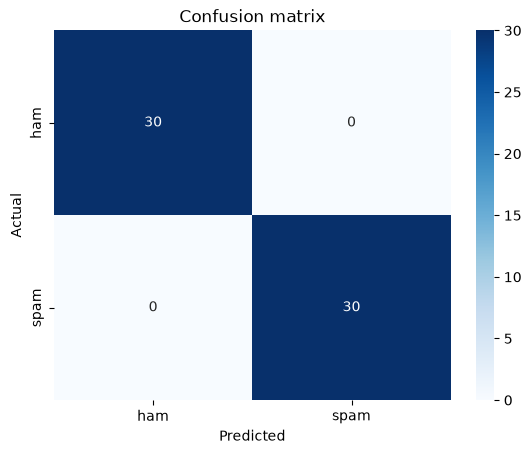

In [45]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["ham", "spam"], yticklabels=["ham", "spam"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Confusion matrix")
plt.show()

### Most spam-indicative / ham-indicative words

In [46]:
feat = np.array(tfidf.get_feature_names_out())
diff = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
pd.DataFrame({"top spam words": feat[np.argsort(diff)[::-1][:10]],
              "top ham words": feat[np.argsort(diff)[:10]]})

,top spam words,top ham words
0,free,pm
1,money,lunch
2,claim,review
3,click,appointment
4,visit,job
5,earn,sorry
6,winner,hey
7,chance claim,inconvenience
8,claim free,move
9,last,sorry inconvenience


### Try it on new messages

In [47]:
def predict_message(msg):
    vec = tfidf.transform([preprocess(msg)])
    proba = nb.predict_proba(vec)[0]
    return {"message": msg, "prediction": "spam" if proba[1] > 0.5 else "ham", "spam_probability": round(float(proba[1]), 3)}

pd.DataFrame([predict_message(m) for m in [
    "Congratulations!! You won a free iPhone, click http://win-big.biz now 🎉",
    "Hey, are we still on for dinner tonight? 😊",
    "URGENT: your bank account is locked, verify at www.secure-login.xyz",
    "Can you send me the meeting notes plz",
]])

,message,prediction,spam_probability
0,"Congratulations!! You won a free iPhone, click http://win-big.biz now 🎉",spam,0.975
1,"Hey, are we still on for dinner tonight? 😊",ham,0.015
2,"URGENT: your bank account is locked, verify at www.secure-login.xyz",spam,0.976
3,Can you send me the meeting notes plz,ham,0.260


## 9. Save the model and vectorizer (for the Streamlit app)

In [30]:
joblib.dump(tfidf, "tfidf_vectorizer.joblib")
joblib.dump(nb, "naive_bayes_model.joblib")

['naive_bayes_model.joblib']